In [1]:
from pathlib import Path
import pickle
import numpy as np

BASE = Path("/kaggle/input/datasets/anishnagargoje/footballviddeo")

VIDEO_PATH = BASE / "08fd33_4.mp4"
TRACKING_PATH = BASE / "tracking_results1.pkl"
HOMOGRAPHY_PATH = BASE / "per_frame_homographies.npz"
WEIGHTS_PATH = BASE / "best (1).pt"

# Verify all required files
for path in [VIDEO_PATH, TRACKING_PATH, HOMOGRAPHY_PATH, WEIGHTS_PATH]:
    print(f"{'FOUND' if path.exists() else ' MISSING'}: {path}")

assert VIDEO_PATH.exists(), "Original video not found"
assert TRACKING_PATH.exists(), "Tracking results not found"
assert HOMOGRAPHY_PATH.exists(), "Calibration data not found"

FOUND: /kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4
FOUND: /kaggle/input/datasets/anishnagargoje/footballviddeo/tracking_results1.pkl
FOUND: /kaggle/input/datasets/anishnagargoje/footballviddeo/per_frame_homographies.npz
FOUND: /kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt


## deleting the uncaliberated frames

In [4]:
from pathlib import Path
import pickle
import numpy as np

# --------------------------------------------------
# 1. Input files
# --------------------------------------------------
BASE = Path("/kaggle/input//datasets/anishnagargoje/footballviddeo")
TRACKING_PATH = BASE / "tracking_results1.pkl"
CALIBRATION_PATH = BASE / "per_frame_homographies.npz"

OUTPUT_DIR = Path("/kaggle/working/FootballVision/phase4_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_TRACKING = OUTPUT_DIR / "calibrated_only_tracking.pkl"
OUTPUT_CALIBRATION = OUTPUT_DIR / "calibrated_only_homographies.npz"

assert TRACKING_PATH.exists(), f"Tracking file missing: {TRACKING_PATH}"
assert CALIBRATION_PATH.exists(), f"Calibration file missing: {CALIBRATION_PATH}"

# --------------------------------------------------
# 2. Load existing data
# --------------------------------------------------
with open(TRACKING_PATH, "rb") as f:
    tracking_data = pickle.load(f)

cal = np.load(CALIBRATION_PATH)

homographies = cal["homographies"]
valid_frames = cal["valid_frames"].astype(bool)

detections = tracking_data["frame_detections"]

assert len(detections) == len(homographies) == len(valid_frames), (
    "Frame counts do not match. Stop rather than misalign the data."
)

# Keep only frames marked calibrated AND containing a finite matrix.
finite_matrices = np.isfinite(homographies).all(axis=(1, 2))
keep_mask = valid_frames & finite_matrices
kept_indices = np.flatnonzero(keep_mask)

assert len(kept_indices) > 0, "No valid calibrated frames found."

# --------------------------------------------------
# 3. Filter tracking and calibration together
# --------------------------------------------------
filtered_tracking = dict(tracking_data)
filtered_tracking["metadata"] = dict(tracking_data["metadata"])

# Preserve the order and correspondence of every kept frame.
filtered_tracking["frame_detections"] = [
    detections[i] for i in kept_indices
]

fps = float(tracking_data["metadata"].get("fps", 25.0))

# These are ORIGINAL video frame indices. Keep them so we know
# exactly when each retained frame occurred in the source video.
filtered_tracking["original_frame_indices"] = kept_indices.tolist()
filtered_tracking["original_timestamps_seconds"] = (
    kept_indices / fps
).tolist()

filtered_tracking["metadata"]["frames"] = len(kept_indices)
filtered_tracking["metadata"]["original_frames"] = len(detections)
filtered_tracking["metadata"]["calibrated_only"] = True

filtered_homographies = homographies[kept_indices]

# --------------------------------------------------
# 4. Save the filtered files
# --------------------------------------------------
with open(OUTPUT_TRACKING, "wb") as f:
    pickle.dump(filtered_tracking, f, protocol=pickle.HIGHEST_PROTOCOL)

np.savez_compressed(
    OUTPUT_CALIBRATION,
    homographies=filtered_homographies,
    valid_frames=np.ones(len(kept_indices), dtype=bool),
    original_frame_indices=kept_indices,
    original_timestamps_seconds=kept_indices / fps,
    fps=np.array(fps),
)

# --------------------------------------------------
# 5. Print summary
# --------------------------------------------------
print("CALIBRATED-ONLY DATASET CREATED")
print("--------------------------------")
print(f"Original frames: {len(detections)}")
print(f"Retained frames: {len(kept_indices)}")
print(f"Excluded frames: {len(detections) - len(kept_indices)}")
print(f"Retention rate: {100 * len(kept_indices) / len(detections):.1f}%")
print(f"\nTracking file:\n{OUTPUT_TRACKING}")
print(f"\nCalibration file:\n{OUTPUT_CALIBRATION}")

print("\nFirst retained original frame indices:", kept_indices[:10].tolist())
print("Last retained original frame indices:", kept_indices[-10:].tolist())

assert len(filtered_tracking["frame_detections"]) == len(filtered_homographies)
print("\nTracking and calibration remain aligned.")

CALIBRATED-ONLY DATASET CREATED
--------------------------------
Original frames: 750
Retained frames: 547
Excluded frames: 203
Retention rate: 72.9%

Tracking file:
/kaggle/working/FootballVision/phase4_training/calibrated_only_tracking.pkl

Calibration file:
/kaggle/working/FootballVision/phase4_training/calibrated_only_homographies.npz

First retained original frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Last retained original frame indices: [740, 741, 742, 743, 744, 745, 746, 747, 748, 749]

Tracking and calibration remain aligned.


## 

## heatmap

Frames being used: 547
These are calibrated frames only.

Saved heatmap: /kaggle/working/FootballVision/phase4_training/footballvision_team_heatmaps.png
Team 0 player observations: 5935
Team 1 player observations: 4885
Goalkeeper tracks: 3


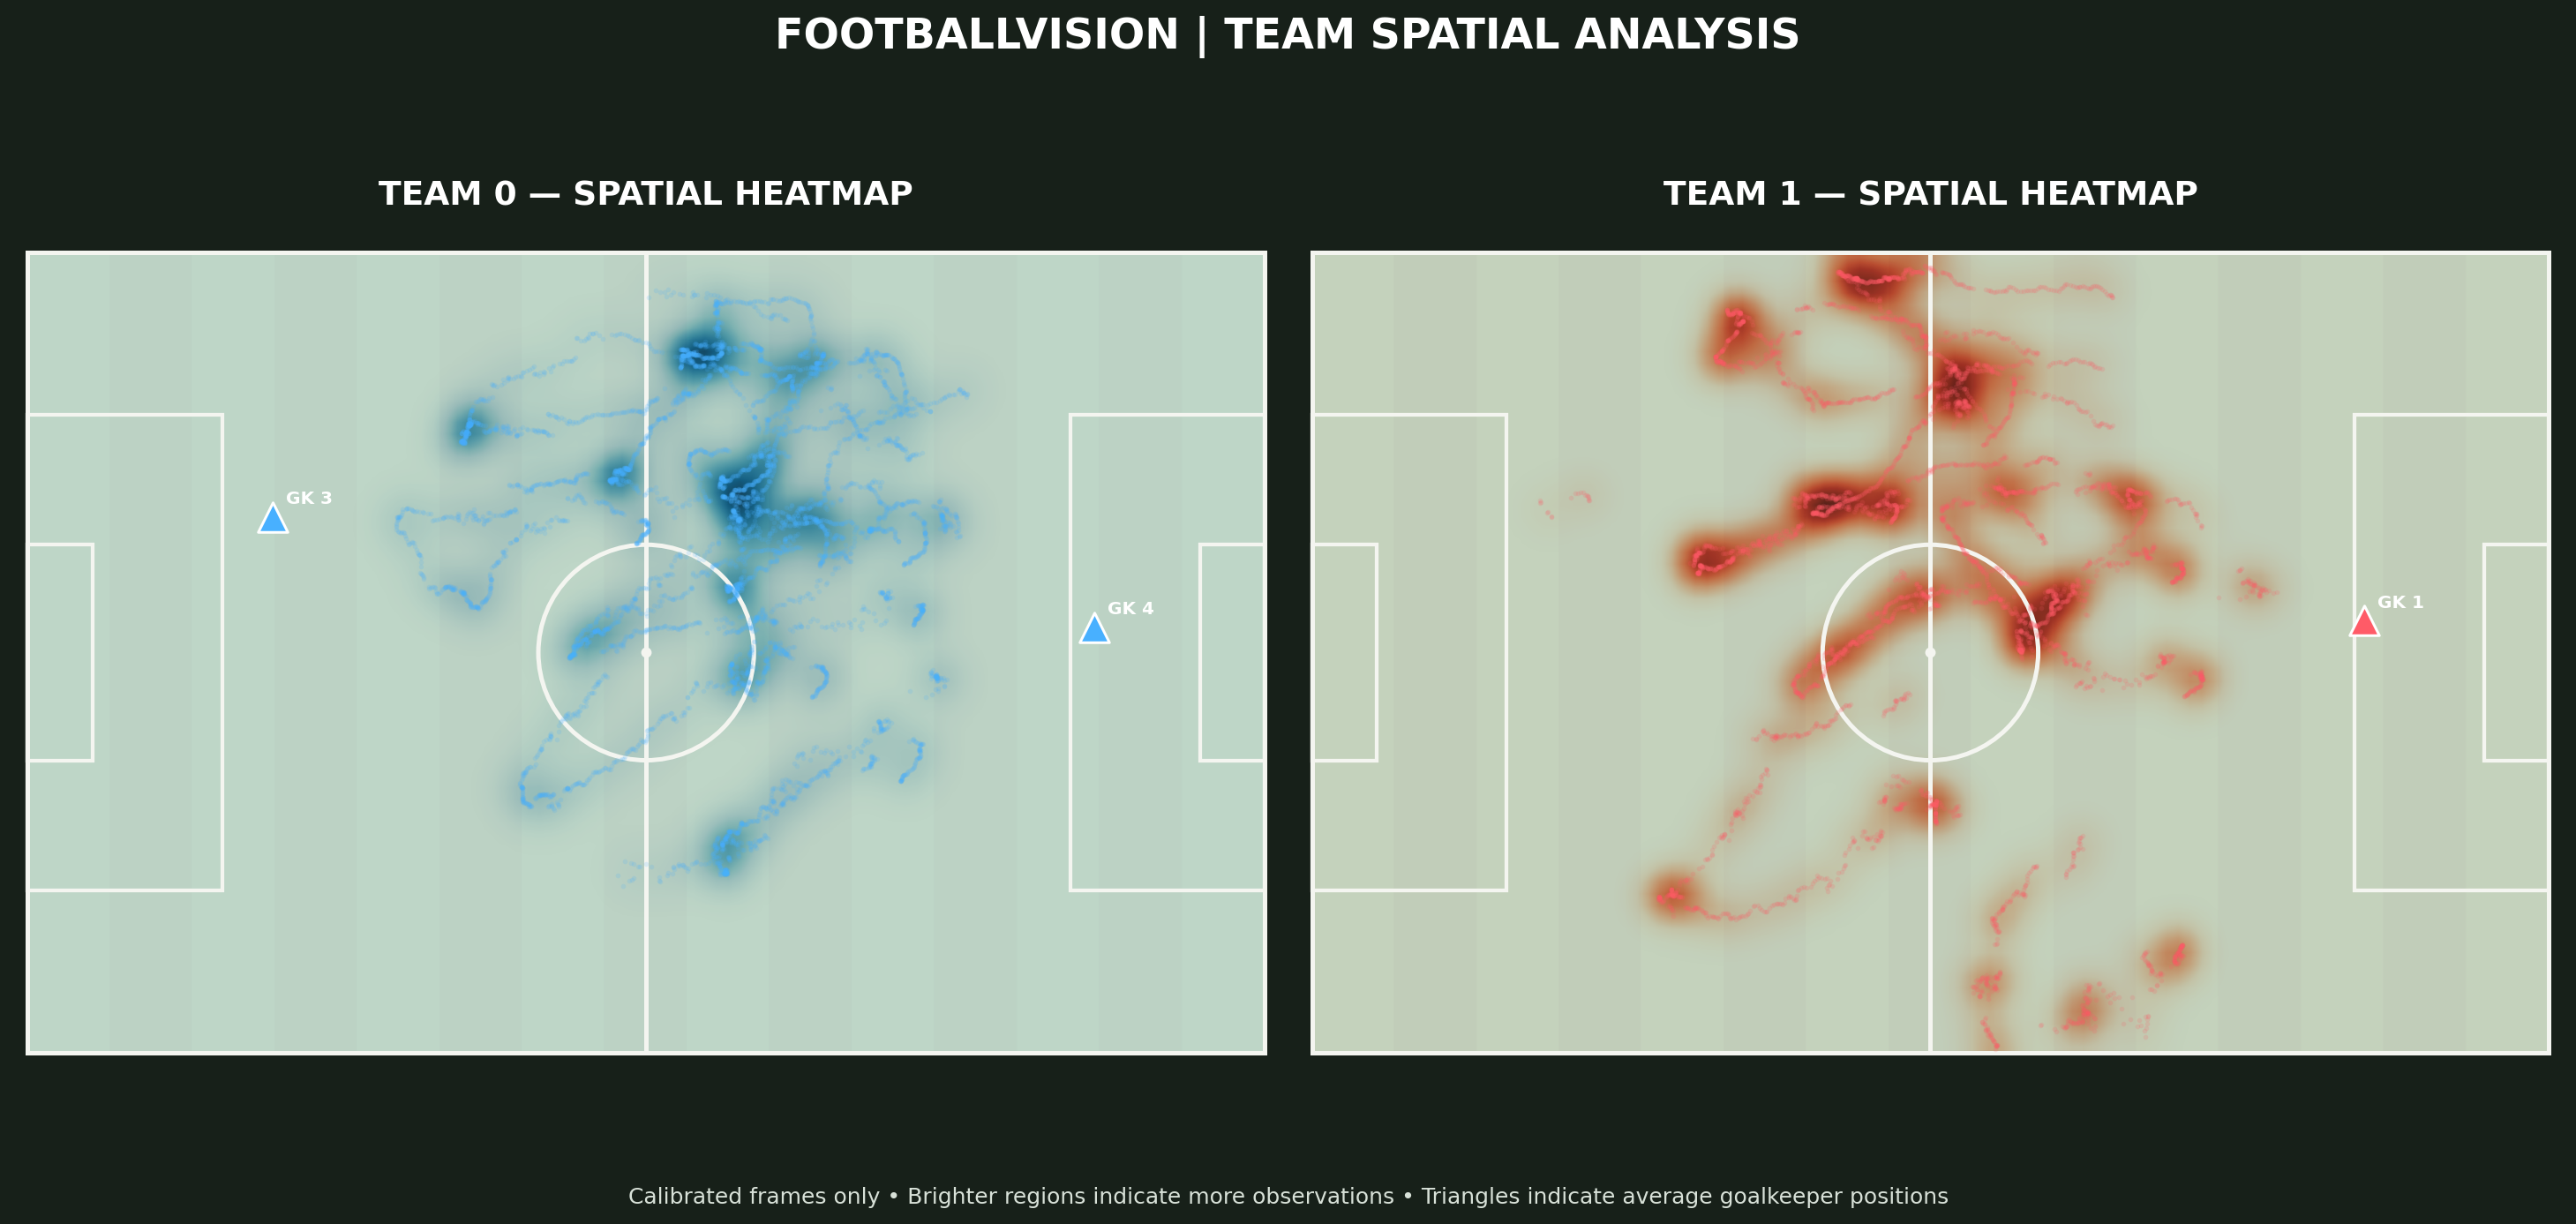

/kaggle/working/FootballVision/phase4_training/footballvision_team_heatmaps.png

In [8]:

from pathlib import Path
import pickle
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from scipy.ndimage import gaussian_filter
from IPython.display import display, FileLink, Image

# ============================================================
# 1. LOAD ONLY THE CALIBRATED DATASET
# ============================================================

OUTPUT_DIR = Path("/kaggle/working/FootballVision/phase4_training")

TRACKING_PATH = OUTPUT_DIR / "calibrated_only_tracking.pkl"
CALIBRATION_PATH = OUTPUT_DIR / "calibrated_only_homographies.npz"

OUTPUT_IMAGE = OUTPUT_DIR / "footballvision_team_heatmaps.png"

assert TRACKING_PATH.exists(), f"Missing filtered tracking: {TRACKING_PATH}"
assert CALIBRATION_PATH.exists(), f"Missing filtered calibration: {CALIBRATION_PATH}"

with open(TRACKING_PATH, "rb") as f:
    tracking = pickle.load(f)

cal = np.load(CALIBRATION_PATH)

detections_by_frame = tracking["frame_detections"]
track_to_team = tracking["track_to_team"]
homographies = cal["homographies"]

LENGTH, WIDTH = 105.0, 68.0
PLAYER_CONF = 0.30
GK_CONF = 0.15

assert len(detections_by_frame) == len(homographies), (
    "Filtered tracking and calibration frame counts do not match."
)

print("Frames being used:", len(detections_by_frame))
print("These are calibrated frames only.")


# ============================================================
# 2. PROJECT PLAYER POSITIONS TO THE PITCH
# ============================================================

team_points = {0: [], 1: []}
goalkeeper_tracks = {}

for frame_idx, detections in enumerate(detections_by_frame):
    H = homographies[frame_idx]

    if not np.isfinite(H).all():
        continue

    for det in detections:
        class_id = det.get("class_id")
        track_id = det.get("track_id")
        confidence = det.get("confidence")
        bbox = det.get("xyxy")

        if class_id not in (1, 2) or track_id is None:
            continue
        if bbox is None or len(bbox) != 4 or confidence is None:
            continue

        class_id = int(class_id)
        confidence = float(confidence)

        if confidence < (GK_CONF if class_id == 1 else PLAYER_CONF):
            continue

        x1, y1, x2, y2 = map(float, bbox)

        # Ground-contact approximation: bottom-centre of the bounding box.
        foot_x = (x1 + x2) / 2.0
        foot_y = y2

        pixel_point = np.array(
            [[[foot_x, foot_y]]], dtype=np.float32
        )

        pitch_x, pitch_y = cv2.perspectiveTransform(
            pixel_point, H
        )[0, 0]

        if not np.isfinite([pitch_x, pitch_y]).all():
            continue

        if not (0 <= pitch_x <= LENGTH and 0 <= pitch_y <= WIDTH):
            continue

        raw_team = track_to_team.get(
            track_id, track_to_team.get(str(track_id), -1)
        )

        try:
            team = int(raw_team)
        except (TypeError, ValueError):
            team = -1

        point = (float(pitch_x), float(pitch_y))

        if class_id == 2 and team in (0, 1):
            team_points[team].append(point)

        elif class_id == 1 and team in (0, 1):
            key = (team, int(track_id))
            goalkeeper_tracks.setdefault(key, []).append(point)


# ============================================================
# 3. BUILD HEATMAPS
# ============================================================

NX, NY = 105, 68
heatmaps = {}

for team in (0, 1):
    points = np.asarray(team_points[team], dtype=float)

    if len(points):
        histogram, _, _ = np.histogram2d(
            points[:, 0],
            points[:, 1],
            bins=[NX, NY],
            range=[[0, LENGTH], [0, WIDTH]],
        )

        # Smooth the accumulated player observations.
        heatmaps[team] = gaussian_filter(histogram.T, sigma=1.5)
    else:
        heatmaps[team] = np.zeros((NY, NX))


# ============================================================
# 4. DRAW A FOOTBALL PITCH
# ============================================================

def draw_pitch(ax, team, title, cmap, team_color):
    ax.set_facecolor("#286b32")

    # Grass stripes.
    for i, x in enumerate(np.arange(0, LENGTH, 7)):
        ax.add_patch(
            Rectangle(
                (x, 0),
                min(7, LENGTH - x),
                WIDTH,
                color="#317a3b" if i % 2 == 0 else "#286b32",
                zorder=0,
            )
        )

    # Heatmap values come only from the filtered calibrated observations.
    heat = heatmaps[team]

    if heat.max() > 0:
        normalized = heat / heat.max()

        ax.imshow(
            normalized,
            extent=(0, LENGTH, 0, WIDTH),
            origin="lower",
            cmap=cmap,
            alpha=0.72,
            interpolation="bilinear",
            vmin=0,
            vmax=1,
            aspect="auto",
            zorder=1,
        )

    white = "#f4f5f0"

    # Outer boundary and halfway line.
    ax.add_patch(
        Rectangle(
            (0, 0), LENGTH, WIDTH,
            fill=False, edgecolor=white, linewidth=2, zorder=2
        )
    )
    ax.plot(
        [LENGTH / 2, LENGTH / 2], [0, WIDTH],
        color=white, linewidth=2, zorder=2
    )

    # Centre circle and spot.
    ax.add_patch(
        Circle(
            (LENGTH / 2, WIDTH / 2),
            9.15,
            fill=False, edgecolor=white, linewidth=2, zorder=2
        )
    )
    ax.scatter(
        [LENGTH / 2], [WIDTH / 2],
        c=white, s=14, zorder=3
    )

    # Penalty and goal areas.
    penalty_depth, penalty_width = 16.5, 40.32
    goal_depth, goal_width = 5.5, 18.32

    for x1, x2, area_width in [
        (0, penalty_depth, penalty_width),
        (LENGTH - penalty_depth, LENGTH, penalty_width),
        (0, goal_depth, goal_width),
        (LENGTH - goal_depth, LENGTH, goal_width),
    ]:
        y1 = (WIDTH - area_width) / 2
        ax.add_patch(
            Rectangle(
                (x1, y1), x2 - x1, area_width,
                fill=False, edgecolor=white, linewidth=1.7, zorder=2
            )
        )

    # Each dot represents a tracked player's average location
    # across observations from calibrated frames.
    points = np.asarray(team_points[team], dtype=float)

    if len(points):
        ax.scatter(
            points[:, 0], points[:, 1],
            s=5, c=team_color, alpha=0.16, linewidths=0, zorder=3
        )

    # Goalkeeper average locations are marked separately.
    for (gk_team, track_id), samples in goalkeeper_tracks.items():
        if gk_team != team or len(samples) < 5:
            continue

        mean_x, mean_y = np.mean(samples, axis=0)

        ax.scatter(
            mean_x, mean_y,
            marker="^", s=180, c=team_color,
            edgecolors="white", linewidths=1.2, zorder=5
        )
        ax.annotate(
            f"GK {track_id}",
            (mean_x, mean_y),
            xytext=(6, 6),
            textcoords="offset points",
            color="white", fontsize=8, fontweight="bold", zorder=6,
        )

    ax.set_xlim(-1, LENGTH + 1)
    ax.set_ylim(-1, WIDTH + 1)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(
        title, color="white", fontsize=15,
        fontweight="bold", pad=16
    )


# ============================================================
# 5. CREATE THE FINAL SIDE-BY-SIDE VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
fig.patch.set_facecolor("#172019")

draw_pitch(
    axes[0], 0,
    "TEAM 0 — SPATIAL HEATMAP",
    "Blues", "#48b0ff"
)

draw_pitch(
    axes[1], 1,
    "TEAM 1 — SPATIAL HEATMAP",
    "Reds", "#ff5b67"
)

fig.suptitle(
    "FOOTBALLVISION | TEAM SPATIAL ANALYSIS",
    color="white", fontsize=19, fontweight="bold", y=0.98
)

fig.text(
    0.5, 0.045,
    "Calibrated frames only • Brighter regions indicate more observations "
    "• Triangles indicate average goalkeeper positions",
    ha="center", color="#d8e1d8", fontsize=10
)

plt.tight_layout(rect=[0.02, 0.08, 0.98, 0.93])

fig.savefig(
    OUTPUT_IMAGE,
    dpi=180,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.close(fig)

print("\nSaved heatmap:", OUTPUT_IMAGE)
print("Team 0 player observations:", len(team_points[0]))
print("Team 1 player observations:", len(team_points[1]))
print("Goalkeeper tracks:", len(goalkeeper_tracks))

display(Image(filename=str(OUTPUT_IMAGE)))
display(FileLink(str(OUTPUT_IMAGE)))


##  possession 

Team 0: 60.4%
Team 1: 39.6%
Saved: /kaggle/working/FootballVision/phase4_training/footballvision_possession_share.png


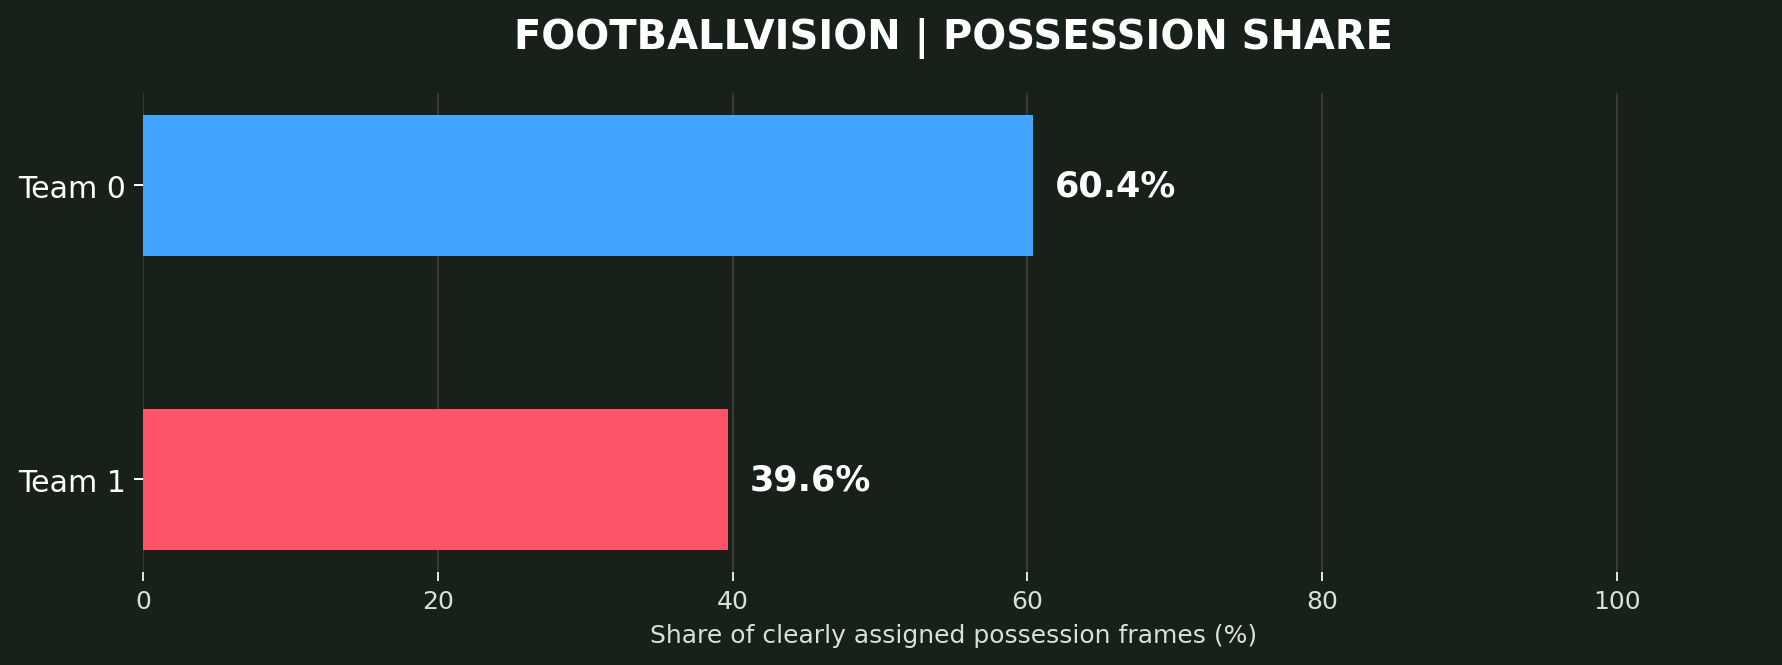

/kaggle/working/FootballVision/phase4_training/footballvision_possession_share.png

In [9]:
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image, FileLink

# Use the possession estimates already calculated in the previous cell.
team0_count = sum(r["state"] == "Team 0" for r in frame_results)
team1_count = sum(r["state"] == "Team 1" for r in frame_results)

total_clear = team0_count + team1_count

if total_clear == 0:
    raise ValueError("No clear possession estimates available.")

team0_share = 100 * team0_count / total_clear
team1_share = 100 * team1_count / total_clear

# Output file
OUTPUT_PATH = Path(
    "/kaggle/working/FootballVision/phase4_training/"
    "footballvision_possession_share.png"
)
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

# Clean, standalone chart
fig, ax = plt.subplots(figsize=(10, 3.8))
fig.patch.set_facecolor("#172019")
ax.set_facecolor("#172019")

teams = ["Team 0", "Team 1"]
shares = [team0_share, team1_share]
colors = ["#42a5ff", "#ff5368"]

bars = ax.barh(
    teams, shares,
    color=colors,
    height=0.48
)

ax.invert_yaxis()
ax.set_xlim(0, 110)

for bar, value in zip(bars, shares):
    ax.text(
        value + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        color="white",
        fontsize=14,
        fontweight="bold"
    )

ax.set_title(
    "FOOTBALLVISION | POSSESSION SHARE",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Share of clearly assigned possession frames (%)",
    color="#d8e1d8",
    fontsize=10
)

ax.tick_params(axis="x", colors="#d8e1d8")
ax.tick_params(axis="y", colors="white", labelsize=12)
ax.grid(axis="x", color="white", alpha=0.12)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
fig.savefig(
    OUTPUT_PATH,
    dpi=180,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)
plt.close(fig)

print(f"Team 0: {team0_share:.1f}%")
print(f"Team 1: {team1_share:.1f}%")
print(f"Saved: {OUTPUT_PATH}")

display(Image(filename=str(OUTPUT_PATH)))
display(FileLink(str(OUTPUT_PATH)))